In [1]:
import gymnasium as gym
from stable_baselines3 import PPO
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

# wind turbine environment

In [2]:


import gymnasium as gym
from gymnasium import spaces

import numpy as np


class WindTurbineEnv(gym.Env):
    """
    Wind turbine digital twin environment
    RL controls yaw velocity
    timestep:
        dt = 1 second
    """

    def __init__(self):
        super().__init__()
        # -------------------------
        # Simulation parameters
        # -------------------------

        self.dt = 1.0     # seconds

        # Turbine parameters
        self.rho = 1.225        # air density
        self.radius = 40        # rotor radius
        self.area = np.pi*self.radius**2

        self.Cp = 0.42          # power coefficient

        # yaw actuator
        self.max_yaw_speed = 1.0  # deg/sec
        
        # Observation space      
        # [wind speed,wind direction,yaw angle,yaw error,power]
        # TODO: normalize
        #env = gym.wrappers.NormalizeObservation(env)
        #env = gym.wrappers.NormalizeReward(env) # Optional auch für Rewards
        low=np.array([3,0,0,-180,0],dtype=np.float32)

        high=np.array([20,360,360,180,10e6],dtype=np.float32)

        self.observation_space = spaces.Box(low,high,dtype=np.float32)
        
        # Action      

        # yaw velocity command
        #
        # -1 deg/s to +1 deg/s

        self.action_space = spaces.Box(
            low=np.array([-1]),
            high=np.array([1]),
            dtype=np.float32
        )
        self.reset()
    

    def reset(self,seed=None,options=None):
        super().reset(seed=seed)
        self.time=0
        self.wind_speed=np.random.uniform(5,12)

        self.wind_direction=np.random.uniform(0,360)

        self.yaw=np.random.uniform(0,360)

        self.power=0
        obs=self.get_state()
        return obs,{}

    

    def wind_model(self):
        """
        Wind simulator
        speed:
        3-20 m/s
        direction:
        0-360 deg
        """
        self.wind_speed = (10+5*np.sin(0.002*self.time)+np.random.normal(0,0.2))

        self.wind_speed=np.clip(self.wind_speed,3,20)

        self.wind_direction += (0.5*np.sin(0.01*self.time)+np.random.normal(0,1))

        self.wind_direction %=360

    def turbine_power(self):
        yaw_error = (self.wind_direction-self.yaw)

        # convert to -180 to 180
        yaw_error = (yaw_error+180)%360-180

        yaw_rad=np.deg2rad(yaw_error)

        # Power equation
        power=(0.5*self.rho*self.area*self.Cp*self.wind_speed**3*np.cos(yaw_rad)**3)

        return max(power,0)


    def get_state(self):

        error=(self.wind_direction-self.yaw)
        error=(error+180)%360-180

        return np.array([self.wind_speed,self.wind_direction,self.yaw,error,self.power/1e6],dtype=np.float32)


    def step(self,action):
        self.time += self.dt

        # yaw actuator    
        yaw_velocity=float(action[0])
        self.yaw += (yaw_velocity*self.dt)
        self.yaw %=360
       
        # wind update      
        self.wind_model()
       
        # power generation       
        self.power=self.turbine_power()

        yaw_error=(self.wind_direction-self.yaw)
        yaw_error=(yaw_error+180)%360-180
        
        # reward    
        reward=(self.power/1e6-0.05*abs(yaw_error)-0.02*abs(yaw_velocity))

        obs=self.get_state()

        terminated=False

        truncated=False

        return (obs,reward,terminated,truncated,{})


### Export Model

In [4]:
"""
import torch
from torchview import draw_graph
import graphviz

env = WindTurbineEnv()
model=PPO(

    policy="MlpPolicy",
    env=env,
    device="cuda" if torch.cuda.is_available() else "cpu",
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    gamma=0.99,
    verbose=1
)

input_shape = (1, *env.observation_space.shape)

model_graph = draw_graph(
    model.policy,
    input_size=input_shape,
    device=model.device, 
    expand_nested=True,  # shows SB3-modlues (mlp_extractor, action_net, value_net)
    hide_inner_tensors=True,
    graph_dir="LR",  # aligning
    save_graph=True,
    filename="ppo_wind_architecture",
)
"""

'\nimport torch\nfrom torchview import draw_graph\nimport graphviz\n\nenv = WindTurbineEnv()\nmodel=PPO(\n\n    policy="MlpPolicy",\n    env=env,\n    device="cuda" if torch.cuda.is_available() else "cpu",\n    learning_rate=3e-4,\n    n_steps=2048,\n    batch_size=64,\n    gamma=0.99,\n    verbose=1\n)\n\ninput_shape = (1, *env.observation_space.shape)\n\nmodel_graph = draw_graph(\n    model.policy,\n    input_size=input_shape,\n    device=model.device, \n    expand_nested=True,  # shows SB3-modlues (mlp_extractor, action_net, value_net)\n    hide_inner_tensors=True,\n    graph_dir="LR",  # aligning\n    save_graph=True,\n    filename="ppo_wind_architecture",\n)\n'

# train PPO

In [3]:

from stable_baselines3 import PPO
import torch
import os

if os.path.exists("ppo_yaw_controller.zip"):
    print("model already trained")
else:
    env=WindTurbineEnv()

    model=PPO(

        policy="MlpPolicy",
        env=env,
        device="cuda" if torch.cuda.is_available() else "cpu",
        learning_rate=3e-4,
        n_steps=2048,
        batch_size=64,
        gamma=0.99,
        verbose=1
    )

    model.learn(
        total_timesteps=300000
    )


    model.save(
        "ppo_yaw_controller"
    )

model already trained


# Custom Models

In [56]:
class CustomWindTurbineEnv(WindTurbineEnv):  # inherits from WindTurbineEnv
# changed reward function
  def step(self, action):
    observation, reward, terminated, truncated, info = super().step(action)
    
    yaw_velocity=float(action[0])
    yaw_error=(self.wind_direction-self.yaw)
    yaw_error=(yaw_error+180)%360-180
    yaw_error = yaw_error
    
    custom_reward = self.power/10e6
    
    return observation, custom_reward, terminated, truncated, info

In [51]:
class CustomWindTurbineEnv(WindTurbineEnv):  # inherits from WindTurbineEnv
# changed power equation
  def efficiency_curve(self, raw_power):
    rated_power = 10e6
    # Normalize raw_power between [0, 1]
    x = raw_power / rated_power

    eta_min = 0.2
    eta_max = 0.92

    # Sigmoid-Function: shift by 0.2
    efficiency = eta_min + (eta_max - eta_min) / (1.0 + np.exp(-15 * (x - 0.2)))

    return efficiency

  def turbine_power(self):
    yaw_error = (self.wind_direction-self.yaw)

    # convert to -180 to 180
    yaw_error = (yaw_error+180)%360-180

    yaw_rad=np.deg2rad(yaw_error)
    betz_factor = 16.0/27.0
    # Power equation
    raw_power=(0.5*self.rho*self.area*self.Cp*self.wind_speed**3*np.cos(yaw_rad)**3)*betz_factor
    efficiency = self.efficiency_curve(raw_power)
    power = raw_power*efficiency
    return max(power,0)

# Train Custom Models

In [58]:
from stable_baselines3 import PPO
import torch
import os

if os.path.exists("custom_ppo_yaw_controller.zip"): #or os.path.exists("custom_ppo_yaw_controller_power.zip"):
    print("model already trained")
else:
    custom_env=CustomWindTurbineEnv()

    custom_model=PPO(

        policy="MlpPolicy",
        env=custom_env,
        device="cuda" if torch.cuda.is_available() else "cpu",
        learning_rate=3e-4,
        n_steps=2048,
        batch_size=64,
        gamma=0.99,
        verbose=1
    )

    custom_model.learn(
        total_timesteps=300000
    )


    custom_model.save(
        "custom_ppo_yaw_controller"
    )

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
-----------------------------
| time/              |      |
|    fps             | 1062 |
|    iterations      | 1    |
|    time_elapsed    | 1    |
|    total_timesteps | 2048 |
-----------------------------
-----------------------------------------
| time/                   |             |
|    fps                  | 818         |
|    iterations           | 2           |
|    time_elapsed         | 5           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.007654484 |
|    clip_fraction        | 0.0724      |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.41       |
|    explained_variance   | -0.016      |
|    learning_rate        | 0.0003      |
|    loss                 | 0.386       |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.00574    |
|    std               

# Test

In [60]:


env=WindTurbineEnv()
custom_env = CustomWindTurbineEnv()

model=PPO.load("ppo_yaw_controller")
custom_model = PPO.load("custom_ppo_yaw_controller")
#custom_model = PPO.load("custom_ppo_yaw_controller_power")

obs,_=env.reset(seed=42)
custom_obs,_ = custom_env.reset(seed=42)

speed=[]
direction=[]
yaw=[]
error=[]
power=[]
energy=[]
total_reward=[]
max_power = []
max_energy = []

total_energy=0
custom_total_energy = 0
max_total_energy = 0
dt = env.dt


for t in range(1000):

    action,_=model.predict(obs)
    custom_action,_ = custom_model.predict(custom_obs)

    obs,reward,done,trunc,_=env.step(action)
    custom_obs, custom_reward, _, _, _ = custom_env.step(custom_action)

    speed.append([obs[0], custom_obs[0]])

    direction.append([obs[1], custom_obs[1]])

    yaw.append([obs[2], custom_obs[2]])

    error.append([obs[3], custom_obs[3]])

    power.append([obs[4], custom_obs[4]])

    power_max = (0.5*env.rho*env.area*env.Cp*obs[0]**3)/1e6
    max_power.append(power_max)
    max_total_energy += power_max * dt/3600
    max_energy.append(max_total_energy)

    total_energy += obs[4] * dt/3600
    custom_total_energy += custom_obs[4] * dt/3600

    energy.append([total_energy, custom_total_energy])

    total_reward.append([reward, custom_reward])

    

# Plot

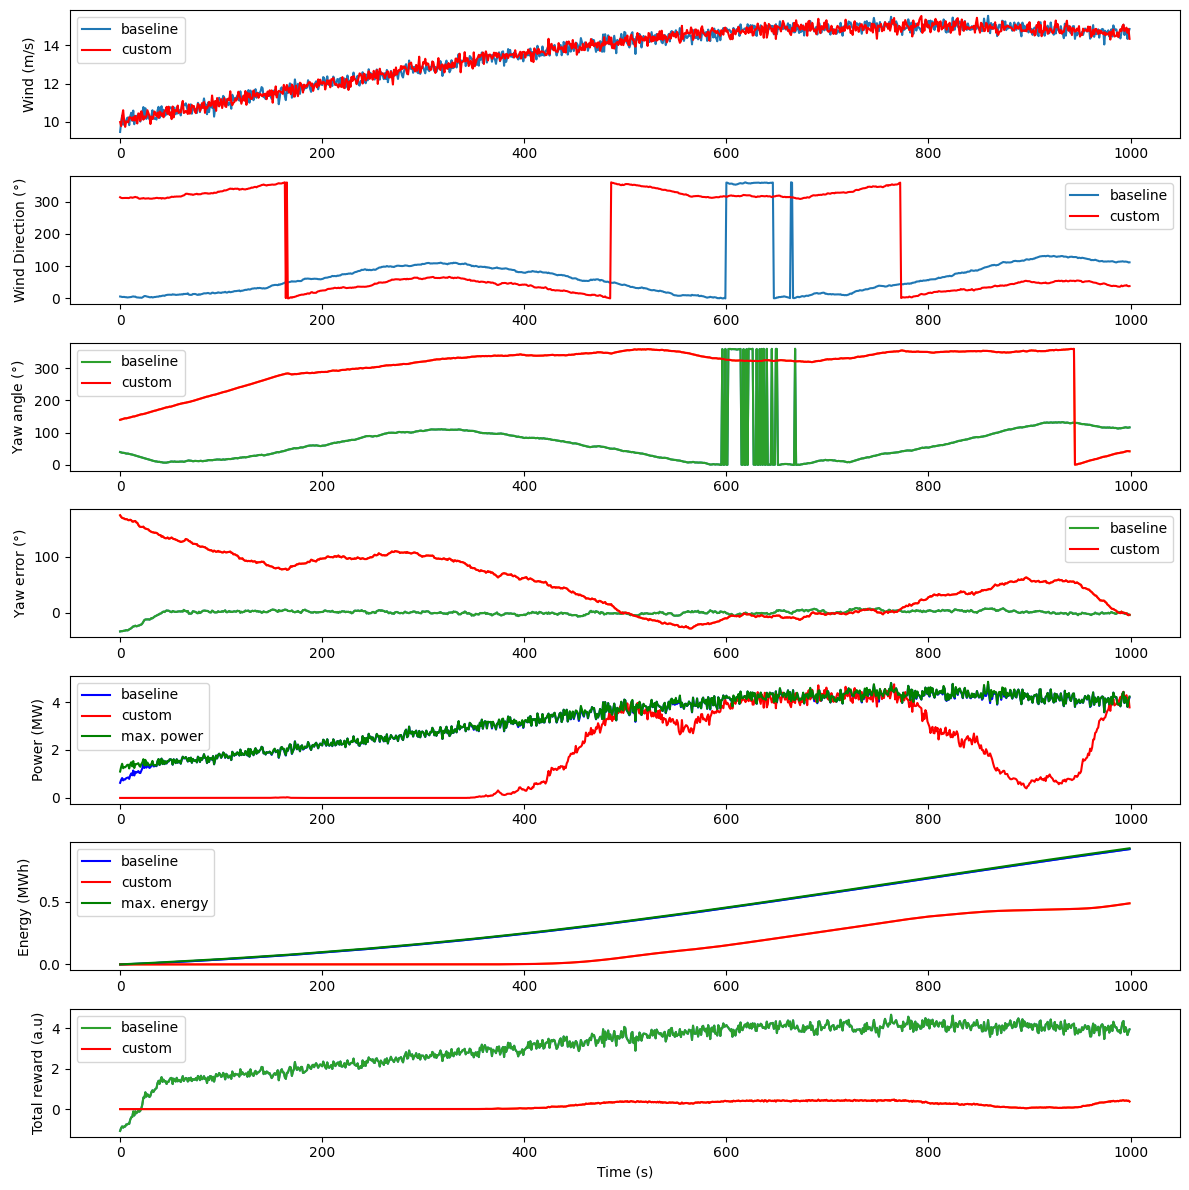

In [61]:
time=np.arange(len(speed))

plt.figure(figsize=(12,12))


plt.subplot(7,1,1)
plt.plot(time,np.array(speed)[:, 0], label="baseline")
plt.plot(time, np.array(speed)[:,1], color="red", label="custom")
plt.ylabel("Wind (m/s)")
plt.legend()

plt.subplot(7,1,2)
plt.plot(time,np.array(direction)[:, 0], label="baseline")
plt.plot(time, np.array(direction)[:,1], color="red", label="custom")
plt.ylabel(r"Wind Direction ($\degree$)")
plt.legend()

plt.subplot(7,1,3)
plt.plot(time,yaw)
plt.plot(time,np.array(yaw)[:, 0], label="baseline")
plt.plot(time, np.array(yaw)[:,1], color="red", label="custom")
plt.ylabel(r"Yaw angle ($\degree$)")
plt.legend()

plt.subplot(7,1,4)
plt.plot(time,error)
plt.plot(time,np.array(error)[:, 0], label="baseline")
plt.plot(time, np.array(error)[:,1], color="red", label="custom")
plt.ylabel(r"Yaw error ($\degree$)")
plt.legend()

plt.subplot(7,1,5)
plt.plot(time,np.array(power)[:, 0], color="blue", label="baseline")
plt.plot(time, np.array(power)[:,1], color="red", label="custom")
plt.plot(time, max_power, color="green", label="max. power")
plt.ylabel("Power (MW)")
plt.legend()

plt.subplot(7,1,6)
plt.plot(time,energy)
plt.plot(time,np.array(energy)[:, 0], color="blue", label="baseline")
plt.plot(time, np.array(energy)[:,1], color="red", label="custom")
plt.plot(time, max_energy, color="green", label="max. energy")
plt.ylabel("Energy (MWh)")
plt.legend()

plt.subplot(7,1,7)
plt.plot(time,total_reward)
plt.plot(time,np.array(total_reward)[:, 0], label="baseline")
plt.plot(time, np.array(total_reward)[:,1], color="red", label="custom")
plt.ylabel("Total reward (a.u)")

plt.xlabel("Time (s)")
plt.legend()

plt.tight_layout()

plt.show()